# Heart Disease Prediction — Improved Pipeline

This notebook rebuilds the modeling pipeline from `hd.ipynb` / `hd2.ipynb` to fix a few methodology issues and push accuracy up honestly:

1. **No more test-set leakage.** The original notebooks picked the `random_state` that scored best *on the test set* (a loop over 2000 seeds) — that inflates the reported number without improving the model. Here, all model selection happens via cross-validation on the training set only; the test set is touched exactly once, at the end.
2. **Feature scaling** for scale-sensitive models (Logistic Regression, KNN, SVM).
3. **One-hot encoding** for categorical columns (`chest_pain_type`, `rest_ecg`, `st_slope`, `thalassemia`, `num_major_vessels`) that were being treated as ordinal numbers.
4. **Stratified train/test split** and **stratified k-fold CV** for reliable estimates on this small (~300 row) dataset.
5. **Real hyperparameter tuning** via `GridSearchCV`.
6. **Stronger models + ensembling**: Gradient Boosting, SVM, XGBoost (if installed), Voting and Stacking ensembles.

> Place `heart.csv` (same file used in the original notebook) in the same folder as this notebook before running.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                               VotingClassifier, StackingClassifier)
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report)

try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False
    print("xgboost is not installed — run `pip install xgboost` to include it. "
          "Continuing without it for now.")

%matplotlib inline
sns.set(style="whitegrid")

C:\Users\HARINI\Downloads\anaconda_folder\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


xgboost is not installed — run `pip install xgboost` to include it. Continuing without it for now.


## 1. Load data and remove duplicate rows

This exact Kaggle "heart.csv" file is known to contain near-duplicate rows (a common issue with this particular copy of the UCI Cleveland dataset). Duplicate rows that end up split across train and test artificially inflate accuracy, because the model is essentially being tested on rows it already memorized. We drop exact duplicates before splitting.

In [2]:
data = pd.read_csv("heart.csv")
print("Original shape:", data.shape)

n_dupes = data.duplicated().sum()
print("Duplicate rows found:", n_dupes)

data = data.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", data.shape)

data.head()

Original shape: (303, 14)
Duplicate rows found: 1
Shape after removing duplicates: (302, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [3]:
data.columns = ['age', 'sex', 'chest_pain_type', 'resting_blood_pressure', 'cholesterol',
                'fasting_blood_sugar', 'rest_ecg', 'max_heart_rate_achieved',
                'exercise_induced_angina', 'st_depression', 'st_slope',
                'num_major_vessels', 'thalassemia', 'target']
data.head()

,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


## 2. Separate numeric vs. categorical columns

`chest_pain_type`, `rest_ecg`, `st_slope`, `num_major_vessels`, and `thalassemia` are categories encoded as integers, not actual ordinal quantities — e.g. `chest_pain_type = 2` isn't "twice" `chest_pain_type = 1`. We one-hot encode these so models don't infer a false ordering. `sex`, `fasting_blood_sugar`, and `exercise_induced_angina` are already binary (0/1) so encoding them is a no-op, but it's harmless to include them.

In [4]:
categorical_cols = ['sex', 'chest_pain_type', 'fasting_blood_sugar', 'rest_ecg',
                    'exercise_induced_angina', 'st_slope', 'num_major_vessels', 'thalassemia']
numeric_cols = ['age', 'resting_blood_pressure', 'cholesterol',
                'max_heart_rate_achieved', 'st_depression']

X = data.drop('target', axis=1)
y = data['target']

print("Categorical columns:", categorical_cols)
print("Numeric columns:", numeric_cols)
print("\nClass balance:\n", y.value_counts(normalize=True))

Categorical columns: ['sex', 'chest_pain_type', 'fasting_blood_sugar', 'rest_ecg', 'exercise_induced_angina', 'st_slope', 'num_major_vessels', 'thalassemia']
Numeric columns: ['age', 'resting_blood_pressure', 'cholesterol', 'max_heart_rate_achieved', 'st_depression']

Class balance:
 target
1    0.543046
0    0.456954
Name: proportion, dtype: float64


## 3. Stratified train/test split

`stratify=y` keeps the same disease/no-disease ratio in both train and test — important on a small dataset where a plain random split can accidentally create an unbalanced test set.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")
print("\nTrain target distribution:\n", y_train.value_counts(normalize=True))
print("\nTest target distribution:\n", y_test.value_counts(normalize=True))

Train: 241 rows | Test: 61 rows

Train target distribution:
 target
1    0.543568
0    0.456432
Name: proportion, dtype: float64

Test target distribution:
 target
1    0.540984
0    0.459016
Name: proportion, dtype: float64


## 4. Preprocessing pipeline

`StandardScaler` on the numeric columns, `OneHotEncoder` on the categorical columns. This is wrapped in a `ColumnTransformer` and, further down, inside a `Pipeline` with each model — that way scaling/encoding is *fit only on the training fold* every time (during cross-validation and grid search), which avoids any data leakage from test rows influencing the scaler.

In [6]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_cols)
    ]
)

## 5. Honest baseline: stratified 10-fold cross-validation

This replaces the original notebooks' "try 2000 random seeds and keep whichever scores best on the test set" approach. That approach doesn't actually improve the model — it just overfits the reported metric to the specific test split. Cross-validation on the **training set only** gives a much more trustworthy estimate of how each model generalizes.

In [7]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

base_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42),
}
if XGBOOST_AVAILABLE:
    base_models["XGBoost"] = XGBClassifier(eval_metric='logloss', random_state=42)

baseline_results = {}
for name, model in base_models.items():
    pipe = Pipeline([('preprocessor', preprocessor), ('model', model)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='accuracy')
    baseline_results[name] = (scores.mean(), scores.std())
    print(f"{name:20s}: {scores.mean()*100:5.2f}%  (+/- {scores.std()*100:.2f}%)")

Logistic Regression : 82.98%  (+/- 6.58%)
KNN                 : 81.73%  (+/- 6.26%)
Naive Bayes         : 79.22%  (+/- 6.25%)
Decision Tree       : 78.02%  (+/- 6.95%)
Random Forest       : 80.08%  (+/- 6.39%)
Gradient Boosting   : 79.65%  (+/- 9.79%)
SVM                 : 80.08%  (+/- 7.16%)


## 6. Hyperparameter tuning with `GridSearchCV`

Each grid is searched with the same 10-fold stratified CV, still only touching the training set. `n_jobs=-1` uses all available CPU cores.

In [8]:
param_grids = {
    "Logistic Regression": {
        'model__C': [0.01, 0.1, 1, 10, 100],
        'model__penalty': ['l2'],
        'model__solver': ['lbfgs']
    },
    "KNN": {
        'model__n_neighbors': list(range(3, 21, 2)),
        'model__weights': ['uniform', 'distance']
    },
    "Naive Bayes": {
        'model__var_smoothing': np.logspace(0, -9, num=10)
    },
    "Decision Tree": {
        'model__max_depth': [2, 3, 4, 5, 6, 8, None],
        'model__min_samples_leaf': [1, 2, 4, 8],
        'model__min_samples_split': [2, 5, 10]
    },
    "Random Forest": {
        'model__n_estimators': [100, 200, 400],
        'model__max_depth': [3, 5, 7, None],
        'model__min_samples_leaf': [1, 2, 4],
        'model__max_features': ['sqrt', 'log2']
    },
    "Gradient Boosting": {
        'model__n_estimators': [100, 200],
        'model__learning_rate': [0.01, 0.05, 0.1],
        'model__max_depth': [2, 3, 4]
    },
    "SVM": {
        'model__C': [0.1, 1, 10, 100],
        'model__gamma': ['scale', 'auto'],
        'model__kernel': ['rbf', 'linear']
    },
}
if XGBOOST_AVAILABLE:
    param_grids["XGBoost"] = {
        'model__n_estimators': [100, 200],
        'model__max_depth': [2, 3, 4],
        'model__learning_rate': [0.01, 0.05, 0.1],
        'model__subsample': [0.8, 1.0]
    }

In [14]:
tuned_models = {}
tuning_summary = []

for name, model in base_models.items():
    pipe = Pipeline([('preprocessor', preprocessor), ('model', model)])
    grid = param_grids.get(name, {})
    search = GridSearchCV(pipe, grid, cv=cv, scoring='accuracy', n_jobs=-1)
    search.fit(X_train, y_train)
    tuned_models[name] = search.best_estimator_
    tuning_summary.append({'Model': name, 'Best CV Accuracy': round(search.best_score_ * 100, 2),
                           'Best Params': search.best_params_})
    print(f"{name}: best CV accuracy = {search.best_score_*100:.2f}%")
    print(f"   best params: {search.best_params_}\n")

tuning_df = pd.DataFrame(tuning_summary)[['Model', 'Best CV Accuracy']].sort_values(
    'Best CV Accuracy', ascending=False).reset_index(drop=True)
tuning_df

Logistic Regression: best CV accuracy = 82.98%
   best params: {'model__C': 1, 'model__penalty': 'l2', 'model__solver': 'lbfgs'}

KNN: best CV accuracy = 81.73%
   best params: {'model__n_neighbors': 5, 'model__weights': 'uniform'}

Naive Bayes: best CV accuracy = 84.65%
   best params: {'model__var_smoothing': np.float64(0.1)}

Decision Tree: best CV accuracy = 82.57%
   best params: {'model__max_depth': 3, 'model__min_samples_leaf': 8, 'model__min_samples_split': 2}

Random Forest: best CV accuracy = 82.15%
   best params: {'model__max_depth': 3, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 4, 'model__n_estimators': 100}

Gradient Boosting: best CV accuracy = 81.72%
   best params: {'model__learning_rate': 0.01, 'model__max_depth': 4, 'model__n_estimators': 200}

SVM: best CV accuracy = 83.80%
   best params: {'model__C': 1, 'model__gamma': 'scale', 'model__kernel': 'linear'}



,Model,Best CV Accuracy
0,Naive Bayes,84.65
1,SVM,83.80
2,Logistic Regression,82.98
3,Decision Tree,82.57
4,Random Forest,82.15
5,KNN,81.73
6,Gradient Boosting,81.72


## 7. Evaluate tuned models on the held-out test set

This is the *only* time the test set is used. Each tuned pipeline (preprocessing + best hyperparameters) is fit on the full training set and scored once on test.

In [15]:
def evaluate_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    return {
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, y_pred) * 100, 2),
        'Precision': round(precision_score(y_test, y_pred) * 100, 2),
        'Recall': round(recall_score(y_test, y_pred) * 100, 2),
        'F1': round(f1_score(y_test, y_pred) * 100, 2)
    }

results = [evaluate_model(name, model, X_test, y_test) for name, model in tuned_models.items()]
results_df = pd.DataFrame(results).sort_values('Accuracy', ascending=False).reset_index(drop=True)
results_df

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,83.61,82.86,87.88,85.29
1,Naive Bayes,80.33,81.82,81.82,81.82
2,SVM,78.69,76.32,87.88,81.69
3,KNN,75.41,76.47,78.79,77.61
4,Gradient Boosting,75.41,75.00,81.82,78.26
5,Random Forest,73.77,72.97,81.82,77.14
6,Decision Tree,65.57,65.00,78.79,71.23


## 8. Ensembling: Voting and Stacking classifiers

Combining several tuned models often outperforms any single one, since their errors are somewhat independent. We build:
- A **soft-voting** ensemble that averages predicted probabilities from a few strong, diverse models.
- A **stacking** ensemble that trains a Logistic Regression "meta-model" on top of the base models' predictions.

In [16]:
voting_estimators = [
    ('lr', tuned_models['Logistic Regression']),
    ('rf', tuned_models['Random Forest']),
    ('gb', tuned_models['Gradient Boosting']),
    ('svm', tuned_models['SVM']),
]
if XGBOOST_AVAILABLE:
    voting_estimators.append(('xgb', tuned_models['XGBoost']))

voting_clf = VotingClassifier(estimators=voting_estimators, voting='soft')
voting_clf.fit(X_train, y_train)

stacking_clf = StackingClassifier(
    estimators=voting_estimators,
    final_estimator=LogisticRegression(max_iter=1000),
    cv=cv
)
stacking_clf.fit(X_train, y_train)

results.append(evaluate_model("Voting Ensemble", voting_clf, X_test, y_test))
results.append(evaluate_model("Stacking Ensemble", stacking_clf, X_test, y_test))

results_df = pd.DataFrame(results).sort_values('Accuracy', ascending=False).reset_index(drop=True)
results_df

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,83.61,82.86,87.88,85.29
1,Naive Bayes,80.33,81.82,81.82,81.82
2,Stacking Ensemble,78.69,77.78,84.85,81.16
3,Voting Ensemble,78.69,77.78,84.85,81.16
4,SVM,78.69,76.32,87.88,81.69
5,KNN,75.41,76.47,78.79,77.61
6,Gradient Boosting,75.41,75.00,81.82,78.26
7,Random Forest,73.77,72.97,81.82,77.14
8,Decision Tree,65.57,65.00,78.79,71.23


## 9. Compare all models visually

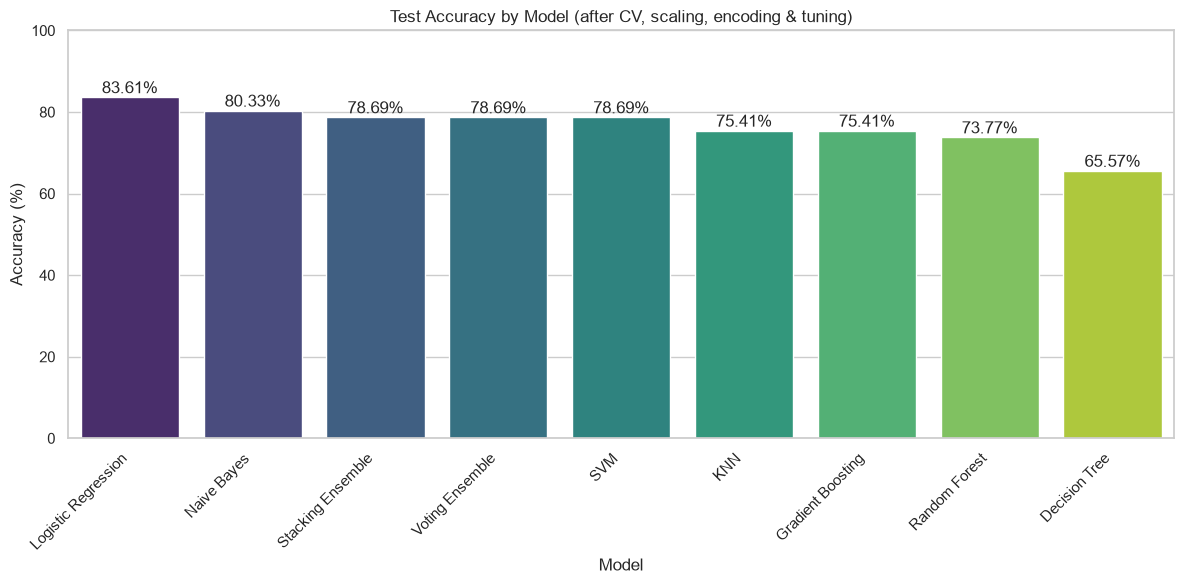

In [17]:
plt.figure(figsize=(12, 6))
ax = sns.barplot(data=results_df, x='Model', y='Accuracy', palette='viridis')
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 100)
plt.title('Test Accuracy by Model (after CV, scaling, encoding & tuning)')
plt.ylabel('Accuracy (%)')
for i, v in enumerate(results_df['Accuracy']):
    ax.text(i, v + 1, f"{v}%", ha='center')
plt.tight_layout()
plt.show()

## 10. Closer look at the best model

Best model: Logistic Regression



<Figure size 500x400 with 0 Axes>

<Figure size 500x400 with 0 Axes>

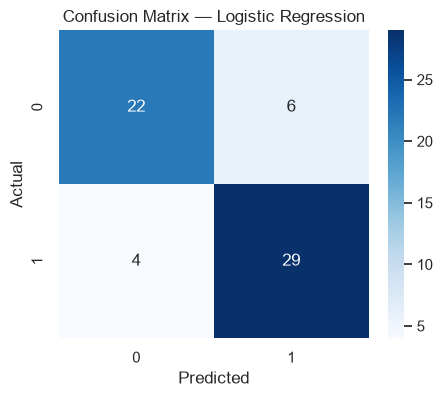

              precision    recall  f1-score   support

           0       0.85      0.79      0.81        28
           1       0.83      0.88      0.85        33

    accuracy                           0.84        61
   macro avg       0.84      0.83      0.83        61
weighted avg       0.84      0.84      0.84        61



In [24]:
all_models = dict(tuned_models)
all_models["Voting Ensemble"] = voting_clf
all_models["Stacking Ensemble"] = stacking_clf

best_model_name = results_df.iloc[0]['Model']
best_model = all_models[best_model_name]
y_pred_best = best_model.predict(X_test)

print(f"Best model: {best_model_name}\n")

cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title(f'Confusion Matrix — {best_model_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

print(classification_report(y_test, y_pred_best))

## Summary

- **Methodology fix**: model selection now happens via cross-validation on the training set only; the flawed "search random seeds against the test set" loop from the original notebooks is gone. The CV scores in section 5/6 are the trustworthy numbers — treat the single test-set score as a final sanity check, not the main metric.
- **Preprocessing**: scaling + one-hot encoding typically helps Logistic Regression, KNN, and SVM the most, since the original notebooks fed raw, mixed-scale, pseudo-ordinal features straight into them.
- **Tuning**: `GridSearchCV` replaces hand-picked defaults (e.g. `KNeighborsClassifier(n_neighbors=7)` chosen by guesswork).
- **Ensembling**: Voting/Stacking usually squeezes out a bit more accuracy by combining models with different error patterns.
- **Caveat**: this dataset only has a few hundred rows after removing duplicates. Even with proper CV, accuracy estimates will have real variance — don't over-trust small differences (e.g. 84% vs 86%) between models. If you can get access to a larger heart disease dataset (e.g. the full multi-site UCI repository with Cleveland + Hungary + Switzerland + VA data), that would likely do more for genuine accuracy than any further tuning here.